In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Christine's Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, auc, precision_recall_curve, roc_curve
from tensorflow.keras.metrics import AUC
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Masking, Dropout, Concatenate
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

icu = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_ICU_Info.csv')
df = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_6h.csv')
df2 = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_2h.csv')

##Peter's Imports (due to different directory structure)
# icu = pd.read_csv('/content/drive/MyDrive/MIMIC_III/A_ICU_Info.csv')
# df = pd.read_csv('/content/drive/MyDrive/MIMIC_III/A_Components_Data.csv')

print("Mortality: ", icu['DEATH'].sum()/icu.shape[0])

Mortality:  0.09380170172536044


In [2]:
df

,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT,HeartRate,...,Norepinephrine,Interval_Num,Time_Elap,SOFA,SOFA_chg,PRE_ICU_LEN,AGE,ADMISSION_TYPE,OASIS,OASIS_chg
0,55973,200001,2181-11-25 19:06:12,5.0,6.0,4.0,15.0,NaN,0,115.0,...,NaN,1,0.000000,3,0.0,171.036667,61,EMERGENCY,17,0.0
1,55973,200001,2181-11-26 01:06:12,5.0,6.0,4.0,15.0,73.000000,0,104.0,...,NaN,2,6.000000,6,3.0,171.036667,61,EMERGENCY,28,11.0
2,55973,200001,2181-11-26 07:06:12,5.0,6.0,4.0,15.0,66.000000,0,90.0,...,NaN,3,12.000000,7,1.0,171.036667,61,EMERGENCY,25,-3.0
3,55973,200001,2181-11-26 13:06:12,5.0,6.0,3.0,14.0,61.000000,0,100.0,...,NaN,4,18.000000,7,0.0,171.036667,61,EMERGENCY,32,7.0
4,55973,200001,2181-11-26 19:06:12,5.0,6.0,4.0,15.0,70.000000,0,91.0,...,NaN,5,24.000000,4,-3.0,171.036667,61,EMERGENCY,27,-5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363530,7630,299999,2117-08-31 21:33:11,5.0,6.0,4.0,15.0,81.000000,1,89.0,...,NaN,3,12.000000,3,3.0,1.553056,49,ELECTIVE,29,23.0
363531,7630,299999,2117-09-01 03:33:11,5.0,6.0,4.0,15.0,70.000000,0,73.0,...,NaN,4,18.000000,2,-1.0,1.553056,49,ELECTIVE,8,-21.0
363532,7630,299999,2117-09-01 09:33:11,5.0,6.0,4.0,15.0,62.666698,0,72.0,...,NaN,5,24.000000,3,1.0,1.553056,49,ELECTIVE,9,1.0
363533,7630,299999,2117-09-01 15:33:11,5.0,6.0,4.0,15.0,67.666702,0,70.0,...,NaN,6,30.000000,1,-2.0,1.553056,49,ELECTIVE,9,0.0


# Experiment 1: Dynamic v.s. Static Score in LSTM (6h baseline)
- Compare the performance of time-series static score and the change in score for LSTM model
- Use the baseline dataset with a time interval of 6h


### **LSTM Modeling**
Tuning<br>
- 'lstm_units': [32, 64, 128]
- 'dropout_rate': [0.1, 0.2, 0.3, 0.5]
- 'dense_units': [16, 32, 64]
- Batch size: [16, 32, 64]
- 'learning_rate': [0.001, 0.0005, 0.0001]
- Bidirectionality: Adding bidirectional LSTMs can improve performance for time-series tasks.

In [ ]:
# Training evaluation
def plot_training_history(history):
    # loss
    plt.figure(figsize=(15, 4))
    plt.subplot(1, 3, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title('Loss Over Epochs')

    # AUC
    plt.subplot(1, 3, 2)
    plt.plot(history.history['roc_auc'], label='Train AUROC')
    plt.plot(history.history['val_roc_auc'], label='Validation AUROC')
    plt.xlabel('Epochs')
    plt.ylabel('AUROC')
    plt.legend()
    plt.title('AUROC Over Epochs')

    # AUPRC
    plt.subplot(1, 3, 3)
    plt.plot(history.history['pr_auc'], label='Train AUPRC')
    plt.plot(history.history['val_pr_auc'], label='Validation AUPRC')
    plt.xlabel('Epochs')
    plt.ylabel('AUPRC')
    plt.legend()
    plt.title('AUPRC Over Epochs')
    plt.show()

In [ ]:
# Test evaluation: PRC and ROC curves
def plot_curves(y_test, y_pred):
    precision, recall, _ = precision_recall_curve(y_test, y_pred)
    pr_auc = auc(recall, precision)

    fpr, tpr, _ = roc_curve(y_test, y_pred)
    roc_auc = auc(fpr, tpr)

    # PR curve
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(recall, precision, label=f'PR AUC = {pr_auc:.4f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()

    # ROC curve
    plt.subplot(1, 2, 2)
    plt.plot(fpr, tpr, label=f'ROC AUC = {roc_auc:.4f}')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend()
    plt.show()

In [ ]:
def LSTM_modeling(sequence, labels, interval, input_shape, lstm_units, dropout_rate, dense_units, batch_size, learning_rate=0.001):
    # Pad sequences to the specified maximum time steps
    maxlen = int(5*24/interval + 1)

    X = pad_sequences(sequence, maxlen = maxlen, dtype='float32', padding='post', value= -100)
    if X.ndim != 3: X = np.expand_dims(X, -1)    # LSTM dimension requirement
    y = labels.values

    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=42)

    model = Sequential([
        Masking(mask_value=-100, input_shape=input_shape),  # Mask padded values
        LSTM(lstm_units, return_sequences=False),                        # Single LSTM layer
        Dropout(dropout_rate),                                            # Dropout to prevent overfitting
        Dense(dense_units, activation='relu'),                           # Dense layer for feature transformation
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')                          # Output layer for binary classification
    ])

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', AUC(name='roc_auc'), AUC(name='pr_auc', curve='PR')])

    # Early stopping if no improvements over 10 subsequent epochs
    early_stopping = EarlyStopping(monitor='val_pr_auc', mode = 'max', patience=10, restore_best_weights=True)

    # Training performance
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=batch_size, callbacks=[early_stopping])
    train_loss, train_accuracy, train_roc_auc, train_pr_auc = model.evaluate(X_train, y_train, verbose=0)
    print(f'Training Loss: {train_loss:.4f}')
    print(f'Training Accuracy: {train_accuracy:.4f}')
    print(f'Training ROC AUC: {train_roc_auc:.4f}')
    print(f'Training PR AUC: {train_pr_auc:.4f}')
    plot_training_history(history)

    y_pred = model.predict(X_test).ravel()

    # Final evaluation metrics
    test_loss, test_accuracy, test_auc, test_pr_auc = model.evaluate(X_test, y_test, verbose=0)
    print(f'Test Loss: {test_loss:.4f}')
    print(f'Test Accuracy: {test_accuracy:.4f}')
    print(f'Test AUC: {test_auc:.4f}')
    print(f'Test PR AUC: {test_pr_auc:.4f}')
    plot_curves(y_test, y_pred)

### **SOFA Score**

In [ ]:
sofa_df = df[['ICUSTAY_ID','SOFA', 'SOFA_chg']]
print("Correlation between static and dynamic score: ", sofa_df['SOFA'].corr(sofa_df['SOFA_chg']))

death_df = icu[['ICUSTAY_ID','DEATH']]
# Merge components data with final expiration label: same label (final status) over time
sofa_df = pd.merge(sofa_df, death_df, on='ICUSTAY_ID')

# Prepare LSTM sequence: all history data
sofa = sofa_df.groupby('ICUSTAY_ID')['SOFA'].apply(list)
sofa_chg = sofa_df.groupby('ICUSTAY_ID')['SOFA_chg'].apply(list)
sofas = df.groupby('ICUSTAY_ID')[['SOFA', 'SOFA_chg']].apply(lambda x: x.values.tolist())
death = sofa_df.groupby('ICUSTAY_ID')['DEATH'].first()   # Extract the first label

Correlation between static and dynamic score:  0.3285445312034477


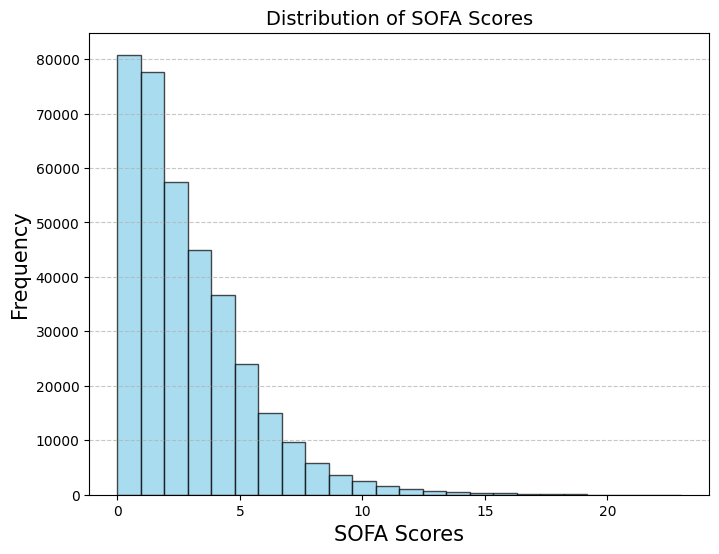

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(sofa_df['SOFA'], bins=24, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution of SOFA Scores', fontsize=14)
plt.xlabel('SOFA Scores', fontsize=15)
plt.ylabel('Frequency', fontsize=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

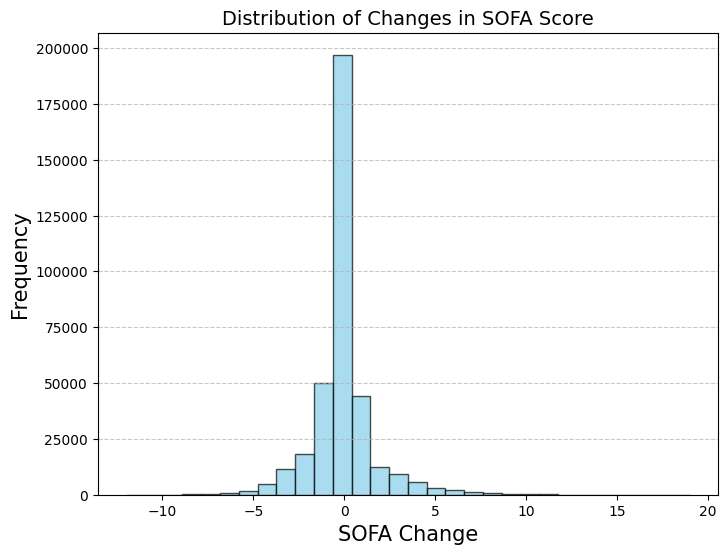

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(sofa_df['SOFA_chg'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution of Changes in SOFA Score', fontsize=14)
plt.xlabel('SOFA Change', fontsize=15)
plt.ylabel('Frequency', fontsize=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9127 - loss: 0.2956 - pr_auc: 0.3391 - roc_auc: 0.7113 - val_accuracy: 0.9306 - val_loss: 0.2120 - val_pr_auc: 0.5854 - val_roc_auc: 0.8586
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9274 - loss: 0.2186 - pr_auc: 0.5656 - roc_auc: 0.8502 - val_accuracy: 0.9306 - val_loss: 0.2069 - val_pr_auc: 0.5964 - val_roc_auc: 0.8619
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9317 - loss: 0.2090 - pr_auc: 0.5826 - roc_auc: 0.8565 - val_accuracy: 0.9328 - val_loss: 0.2043 - val_pr_auc: 0.6036 - val_roc_auc: 0.8632
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9331 - loss: 0.2081 - pr_auc: 0.5903 - roc_auc: 0.8585 - val_accuracy: 0.9337 - val_loss: 0.2003 - val_pr_auc: 0.6163 - val_roc_auc: 0.8686
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9336 - loss: 0.2057 - pr_auc: 0.6023 - roc_auc: 0.8606 - val_accuracy: 0.9345 - val_loss: 0.1980 - val_pr_au

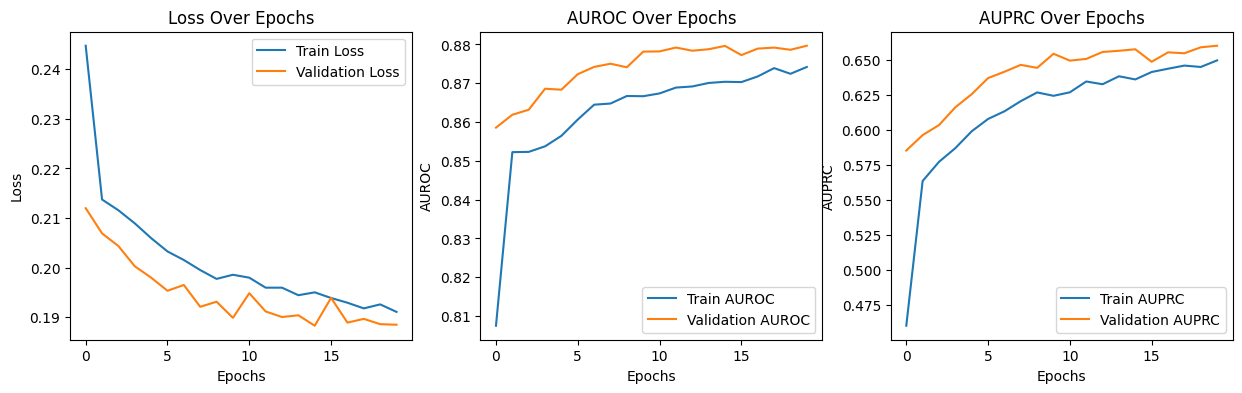

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.2034
Test Accuracy: 0.9346
Test AUC: 0.8598
Test PR AUC: 0.6097


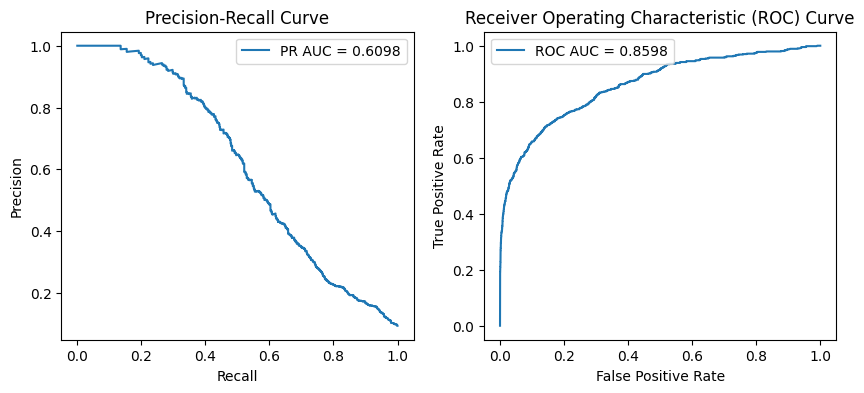

In [ ]:
LSTM_modeling(sofa, death, interval = 6, input_shape= (21,1), lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9185 - loss: 0.3267 - pr_auc: 0.2537 - roc_auc: 0.6420 - val_accuracy: 0.9273 - val_loss: 0.2236 - val_pr_auc: 0.5607 - val_roc_auc: 0.8299
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9297 - loss: 0.2151 - pr_auc: 0.5639 - roc_auc: 0.8253 - val_accuracy: 0.9297 - val_loss: 0.2159 - val_pr_auc: 0.5717 - val_roc_auc: 0.8309
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9324 - loss: 0.2157 - pr_auc: 0.5695 - roc_auc: 0.8193 - val_accuracy: 0.9298 - val_loss: 0.2138 - val_pr_auc: 0.5765 - val_roc_auc: 0.8364
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9302 - loss: 0.2180 - pr_auc: 0.5735 - roc_auc: 0.8262 - val_accuracy: 0.9319 - val_loss: 0.2136 - val_pr_auc: 0.5806 - val_roc_auc: 0.8341
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9283 - loss: 0.2231 - pr_auc: 0.5733 - roc_auc: 0.8234 - val_accuracy: 0.9313 - val_loss: 0.2139 - val_pr_auc: 0.5855 - v

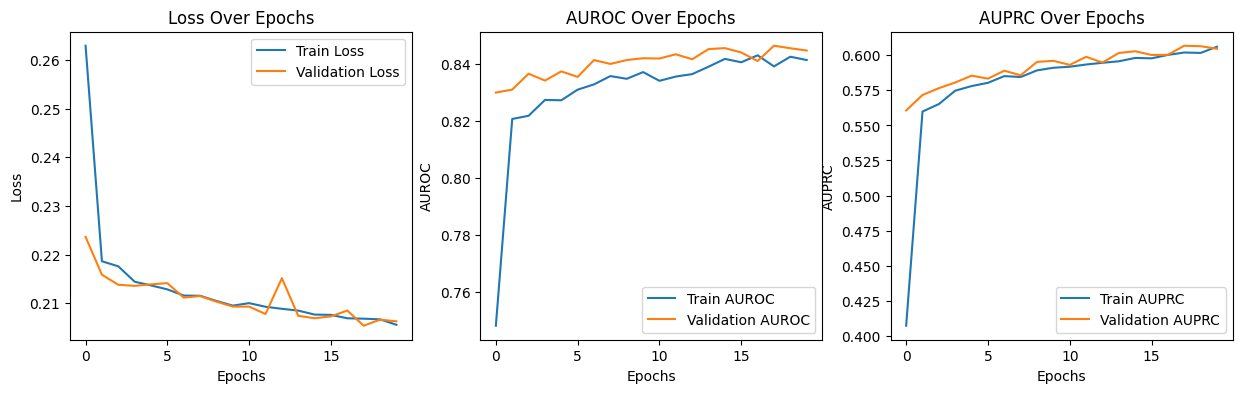

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.2146
Test Accuracy: 0.9315
Test AUC: 0.8423
Test PR AUC: 0.5695


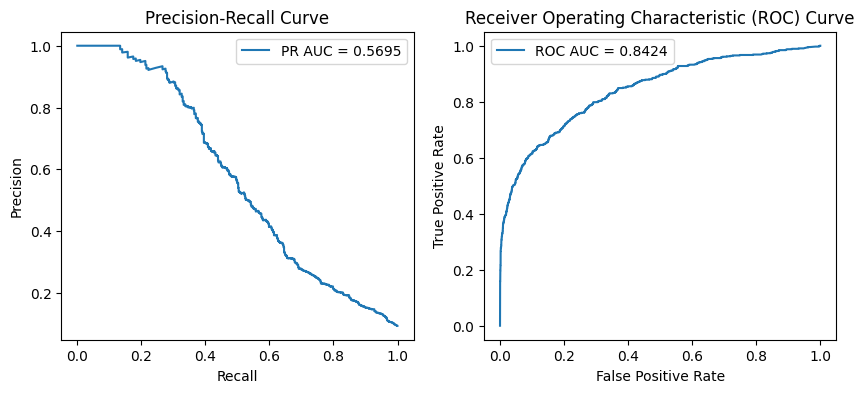

In [ ]:
# Only change in Sofa score
LSTM_modeling(sofa_chg, death, interval = 6, input_shape= (21,1), lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

(21662, 21, 2, 1)
Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9129 - loss: 0.2876 - pr_auc: 0.3740 - roc_auc: 0.7342 - val_accuracy: 0.9361 - val_loss: 0.1983 - val_pr_auc: 0.6288 - val_roc_auc: 0.8678
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9344 - loss: 0.2054 - pr_auc: 0.6200 - roc_auc: 0.8599 - val_accuracy: 0.9365 - val_loss: 0.1942 - val_pr_auc: 0.6407 - val_roc_auc: 0.8732
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9342 - loss: 0.2061 - pr_auc: 0.6114 - roc_auc: 0.8547 - val_accuracy: 0.9367 - val_loss: 0.1932 - val_pr_auc: 0.6453 - val_roc_auc: 0.8742
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9358 - loss: 0.2008 - pr_auc: 0.6247 - roc_auc: 0.8610 - val_accuracy: 0.9372 - val_loss: 0.1925 - val_pr_auc: 0.6488 - val_roc_auc: 0.8755
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9371 - loss: 0.1946 - pr_auc: 0.6239 - roc_auc: 0.8724 - val_accuracy: 0.9367 - val_loss: 0.1912 - val_pr_auc: 0.6515 - v

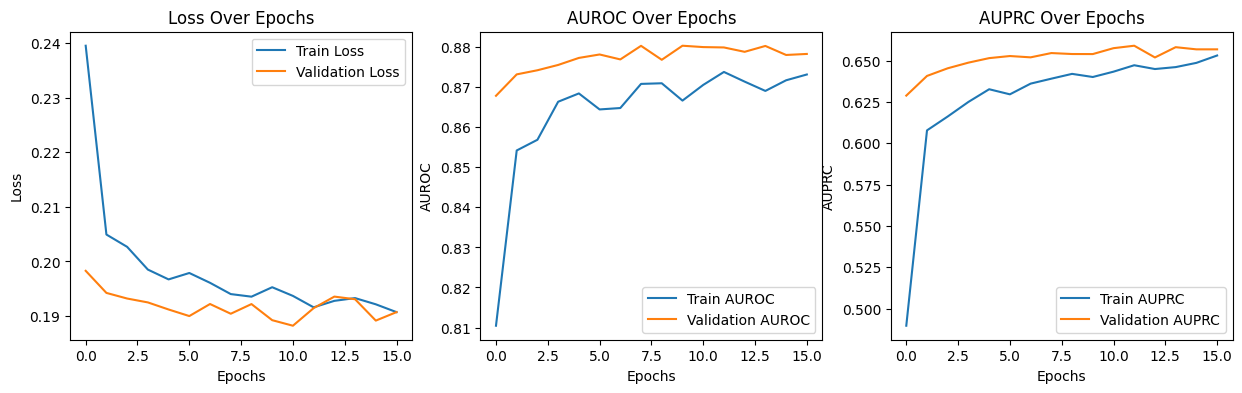

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test Loss: 0.1996
Test Accuracy: 0.9355
Test AUC: 0.8630
Test PR AUC: 0.6246


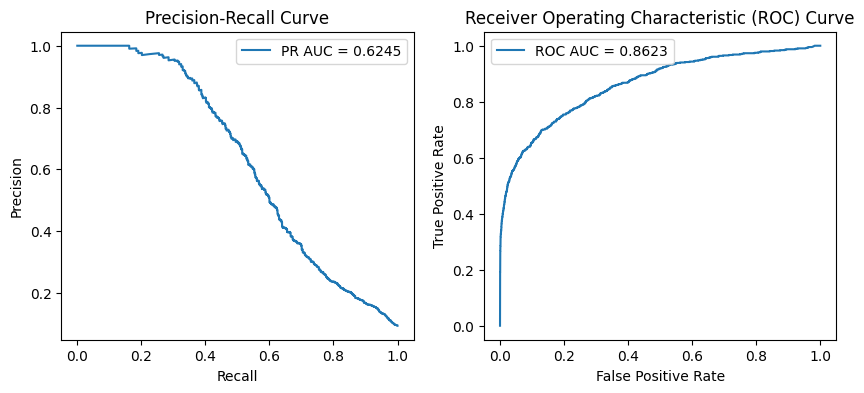

In [ ]:
# Both static and dynamic Sofa score
LSTM_modeling(sofas, death, interval = 6, input_shape= (21,2), lstm_units = 64, dropout_rate = 0, dense_units = 32, batch_size = 32)

### **OSASIS Score**

In [ ]:
oasis_df = df[['ICUSTAY_ID','OASIS', 'OASIS_chg']]
print("Correlation between static and dynamic score: ", oasis_df['OASIS'].corr(oasis_df['OASIS_chg']))

death_df = icu[['ICUSTAY_ID','DEATH']]
# Merge components data with final expiration label: same label (final status) over time
oasis_df = pd.merge(oasis_df, death_df, on='ICUSTAY_ID')

# Prepare LSTM sequence: all history data
oasis = oasis_df.groupby('ICUSTAY_ID')['OASIS'].apply(list)
oasis_chg = oasis_df.groupby('ICUSTAY_ID')['OASIS_chg'].apply(list)
oasiss = df.groupby('ICUSTAY_ID')[['OASIS', 'OASIS_chg']].apply(lambda x: x.values.tolist())
death = oasis_df.groupby('ICUSTAY_ID')['DEATH'].first()   # Extract the first label

Correlation between static and dynamic score:  0.36469465896157904


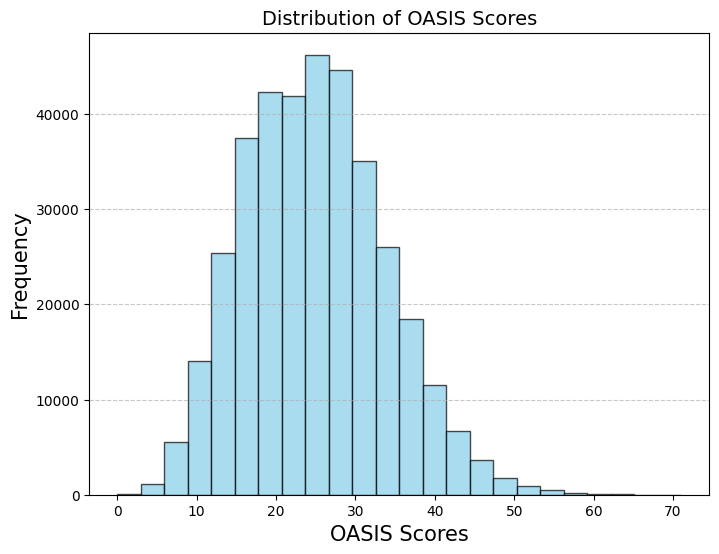

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(oasis_df['OASIS'], bins=24, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution of OASIS Scores', fontsize=14)
plt.xlabel('OASIS Scores', fontsize=15)
plt.ylabel('Frequency', fontsize=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

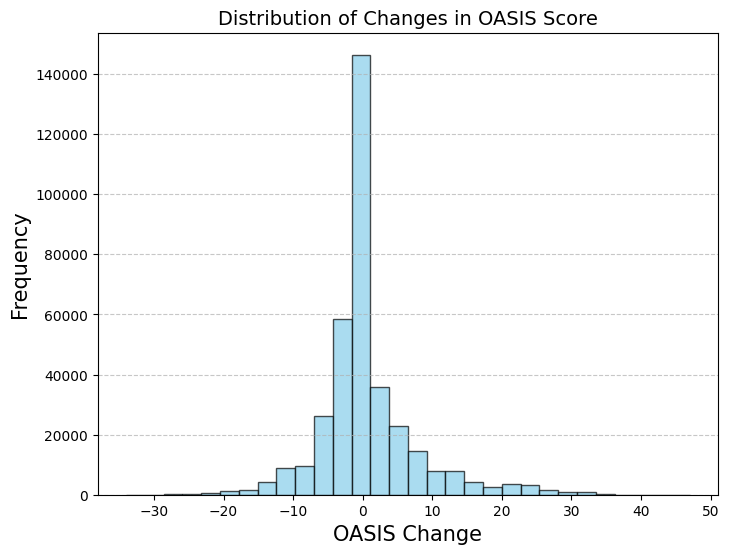

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(oasis_df['OASIS_chg'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution of Changes in OASIS Score', fontsize=14)
plt.xlabel('OASIS Change', fontsize=15)
plt.ylabel('Frequency', fontsize=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8846 - loss: 0.3096 - pr_auc: 0.2480 - roc_auc: 0.7021 - val_accuracy: 0.9278 - val_loss: 0.2256 - val_pr_auc: 0.5523 - val_roc_auc: 0.8270
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9274 - loss: 0.2302 - pr_auc: 0.5033 - roc_auc: 0.8025 - val_accuracy: 0.9282 - val_loss: 0.2199 - val_pr_auc: 0.5652 - val_roc_auc: 0.8314
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9291 - loss: 0.2306 - pr_auc: 0.4948 - roc_auc: 0.7893 - val_accuracy: 0.9298 - val_loss: 0.2167 - val_pr_auc: 0.5726 - val_roc_auc: 0.8342
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9268 - loss: 0.2346 - pr_auc: 0.5132 - roc_auc: 0.7915 - val_accuracy: 0.9309 - val_loss: 0.2164 - val_pr_auc: 0.5738 - val_roc_auc: 0.8374
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9268 - loss: 0.2318 - pr_auc: 0.5313 - roc_auc: 0.8098 - val_accuracy: 0.9300 - val_loss: 0.2172 - val_pr_auc: 0.5797 - v

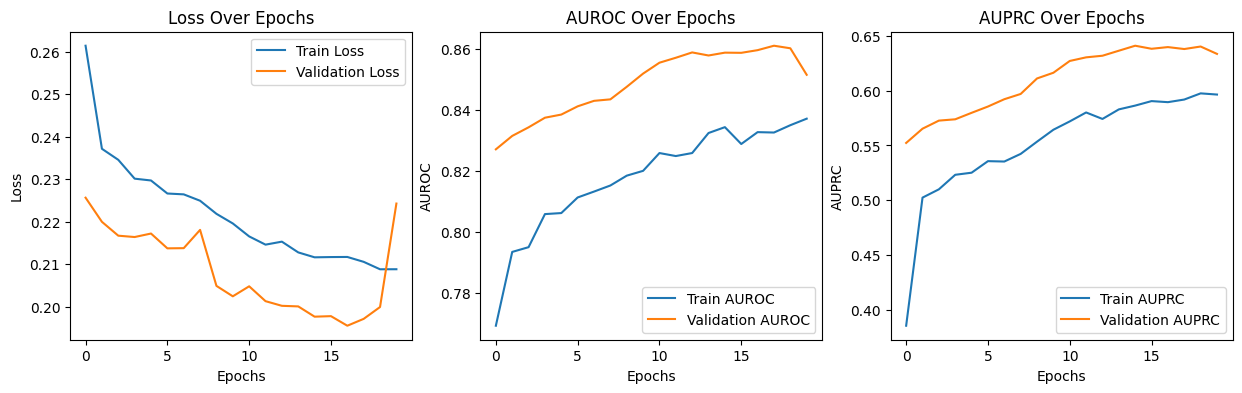

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test Loss: 0.2080
Test Accuracy: 0.9344
Test AUC: 0.8495
Test PR AUC: 0.5941


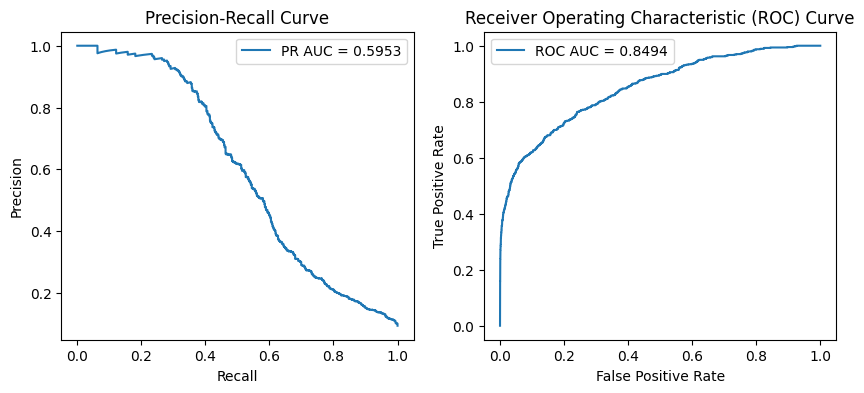

In [ ]:
LSTM_modeling(oasis, death, interval = 6, input_shape= (21,1), lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9164 - loss: 0.2737 - pr_auc: 0.3323 - roc_auc: 0.7296 - val_accuracy: 0.9284 - val_loss: 0.2221 - val_pr_auc: 0.5569 - val_roc_auc: 0.8258
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9234 - loss: 0.2429 - pr_auc: 0.5065 - roc_auc: 0.7943 - val_accuracy: 0.9300 - val_loss: 0.2217 - val_pr_auc: 0.5662 - val_roc_auc: 0.8307
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9233 - loss: 0.2389 - pr_auc: 0.5050 - roc_auc: 0.7982 - val_accuracy: 0.9295 - val_loss: 0.2178 - val_pr_auc: 0.5660 - val_roc_auc: 0.8323
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9268 - loss: 0.2323 - pr_auc: 0.5070 - roc_auc: 0.8004 - val_accuracy: 0.9315 - val_loss: 0.2145 - val_pr_auc: 0.5735 - val_roc_auc: 0.8362
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9278 - loss: 0.2280 - pr_auc: 0.5328 - roc_auc: 0.8105 - val_accuracy: 0.9326 - val_loss: 0.2189 - val_pr_auc: 0.5801 - v

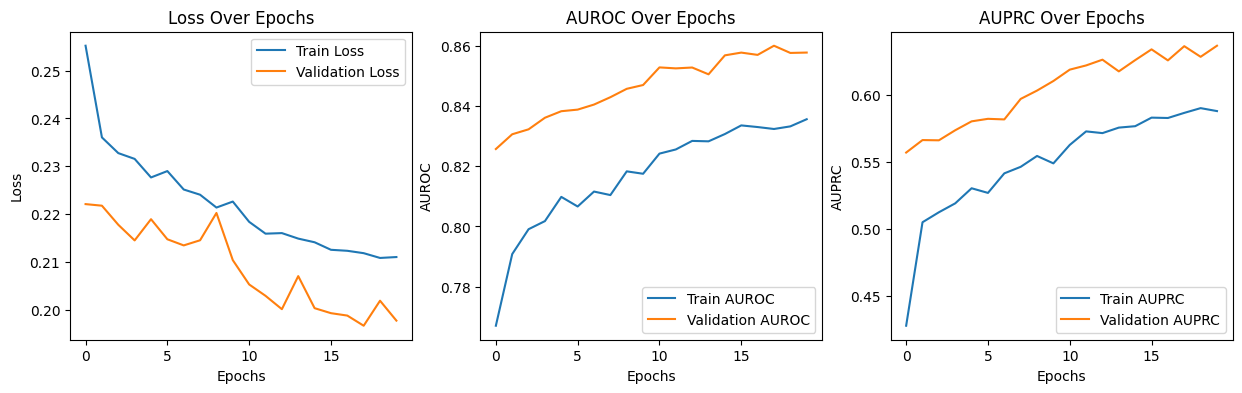

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test Loss: 0.2091
Test Accuracy: 0.9331
Test AUC: 0.8459
Test PR AUC: 0.5893


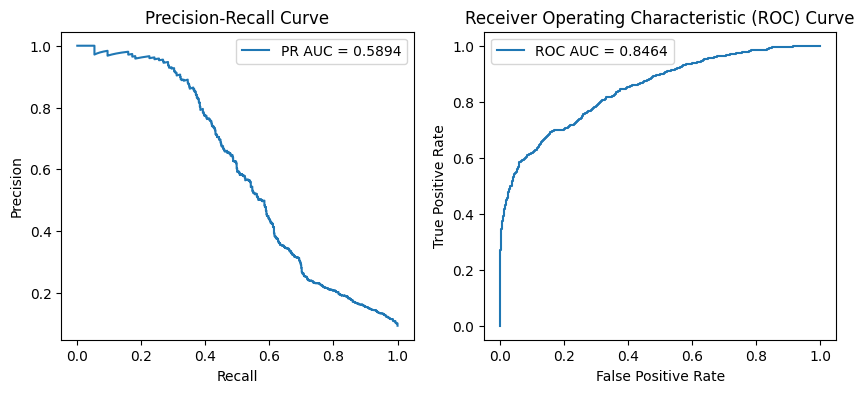

In [ ]:
# Only change in OASIS score
LSTM_modeling(oasis_chg, death, interval = 6, input_shape= (21,1), lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


677/677 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9202 - loss: 0.2546 - pr_auc: 0.3800 - roc_auc: 0.7714 - val_accuracy: 0.9380 - val_loss: 0.1993 - val_pr_auc: 0.6336 - val_roc_auc: 0.8583
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9348 - loss: 0.2086 - pr_auc: 0.5883 - roc_auc: 0.8338 - val_accuracy: 0.9393 - val_loss: 0.2001 - val_pr_auc: 0.6384 - val_roc_auc: 0.8596
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9336 - loss: 0.2112 - pr_auc: 0.6081 - roc_auc: 0.8433 - val_accuracy: 0.9385 - val_loss: 0.1962 - val_pr_auc: 0.6375 - val_roc_auc: 0.8587
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9342 - loss: 0.2085 - pr_auc: 0.6235 - roc_auc: 0.8513 - val_accuracy: 0.9372 - val_loss: 0.1948 - val_pr_auc: 0.6409 - val_roc_auc: 0.8613
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9333 - loss: 0.2087 - pr_auc: 0.5959 - roc_auc: 0.8385 - val_accuracy: 0.9391 - val_loss: 0.1931 - val_pr_auc: 0.6443 - v

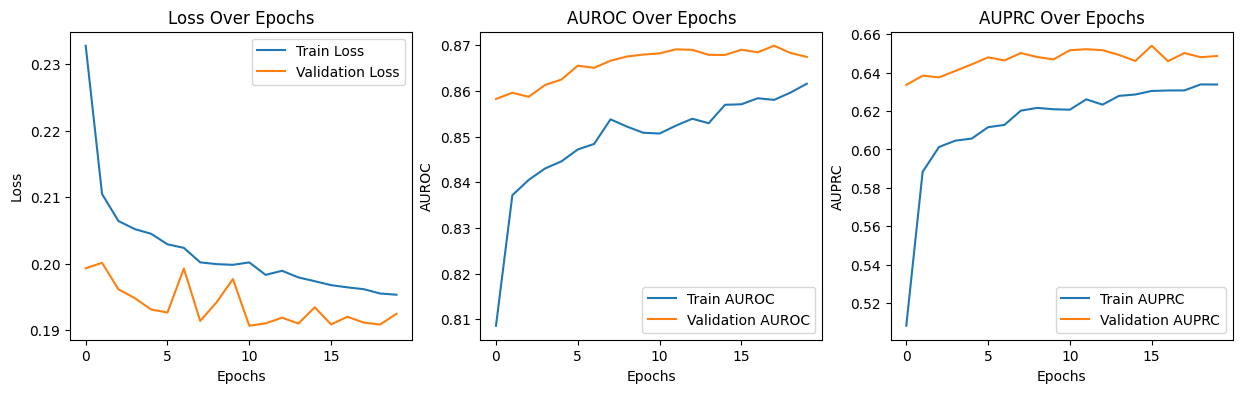

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test Loss: 0.2045
Test Accuracy: 0.9347
Test AUC: 0.8621
Test PR AUC: 0.6043


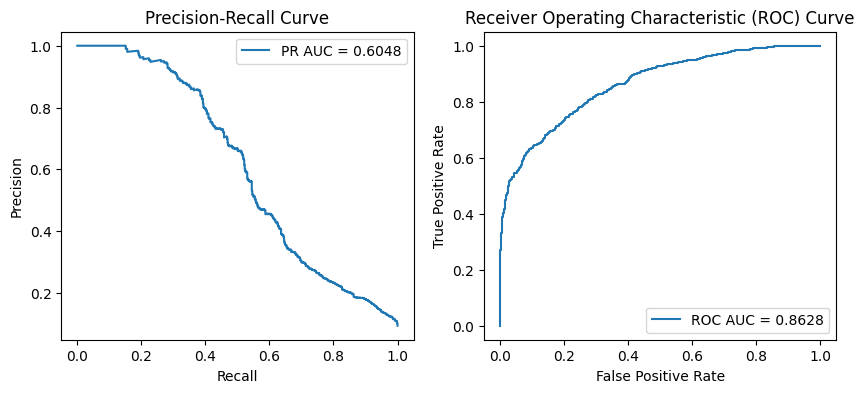

In [ ]:
# Both static and dynamic OASIS score
LSTM_modeling(oasiss, death, interval = 6, input_shape= (21,2), lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

# Experiment 2: Major Metrics v.s. All Components in LSTM (6h & 2h)
- Compare modeling with proposed key metrics (SOFA, SOFA_chg, OASIS, OASIS_chg, LOS) and along all available components
- Compare performance of time interval of 6h v.s. 2h

### **LSTM Modeling**

In [ ]:
def LSTM_all(sequence, static, labels, interval, lstm_units, dropout_rate, dense_units, batch_size, learning_rate=0.001):
    # Pad sequences to the specified maximum time steps
    maxlen = int(5*24/interval + 1)

    X = pad_sequences(sequence, maxlen = maxlen, dtype='float32', padding='post', value= -100)
    if X.ndim != 3: X = np.expand_dims(X, -1)    # LSTM dimension requirement

    y = labels.values

    static_data = static.values
    if static_data.ndim == 1:
        static_data = np.expand_dims(static_data, axis=-1)

    X_temp, X_test, static_temp, static_test, y_temp, y_test = train_test_split(X, static_data, y, test_size=0.2, stratify=y, random_state=42)
    X_train, X_val, static_train, static_val, y_train, y_val = train_test_split(X_temp,static_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=42)

    # Define inputs for time-series and static features
    time_input = Input(shape=(X_train.shape[1], X_train.shape[2]), name="time_input")
    x = Masking(mask_value=-100)(time_input)    # Mask padded values
    x = LSTM(lstm_units, return_sequences=False)(x)   # Single LSTM layer
    x = Dropout(dropout_rate)(x)      # Dropout to prevent overfitting

    static_input_dim = static_train.shape[1]
    static_input = Input(shape=(static_input_dim,), name="static_input")
    y = Dense(16, activation="relu")(static_input)
    y = Dropout(dropout_rate)(y)

    # Combine both inputs
    combined = Concatenate()([x, y])
    z = Dense(dense_units, activation="relu")(combined)   # Dense layer for feature transformation
    z = Dropout(dropout_rate)(z)
    output = Dense(1, activation="sigmoid")(z)

    model = Model(inputs=[time_input, static_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', AUC(name='roc_auc'), AUC(name='pr_auc', curve='PR')])

    # Early stopping if no improvements over 10 subsequent epochs
    early_stopping = EarlyStopping(monitor='val_pr_auc', mode = 'max', patience=10, restore_best_weights=True)

    # Training performance
    history = model.fit(
        [X_train, static_train],
        y_train,
        validation_data=([X_val, static_val], y_val),
        epochs=20,
        batch_size = batch_size,
        callbacks=[early_stopping],
    )

    train_loss, train_accuracy, train_roc_auc, train_pr_auc = model.evaluate([X_train, static_train], y_train, verbose=0)
    print(f'Training Loss: {train_loss:.4f}')
    print(f'Training Accuracy: {train_accuracy:.4f}')
    print(f'Training ROC AUC: {train_roc_auc:.4f}')
    print(f'Training PR AUC: {train_pr_auc:.4f}')
    plot_training_history(history)

    y_pred = model.predict([X_test, static_test]).ravel()

    # Final evaluation metrics
    test_loss, test_accuracy, test_auc, test_pr_auc = model.evaluate([X_test, static_test], y_test, verbose=0)
    print(f'Test Loss: {test_loss:.4f}')
    print(f'Test Accuracy: {test_accuracy:.4f}')
    print(f'Test AUC: {test_auc:.4f}')
    print(f'Test PR AUC: {test_pr_auc:.4f}')
    plot_curves(y_test, y_pred)

### Major Metrics

In [ ]:
def process_metrics(df):
    metrics_cols = ['SOFA', 'SOFA_chg', 'OASIS', 'OASIS_chg','ICUSTAY_ID']
    metrics_df = df[metrics_cols]

    static_df = icu[['ICUSTAY_ID','DEATH','LOS']]
    metrics_df = pd.merge(metrics_df, static_df, on='ICUSTAY_ID')

    metrics = metrics_df.groupby('ICUSTAY_ID')[metrics_cols[0:4]].apply(lambda x: x.values.tolist())
    los = metrics_df.groupby('ICUSTAY_ID')['LOS'].first()   # Extract the first los
    death = metrics_df.groupby('ICUSTAY_ID')['DEATH'].first()   # Extract the first label
    return metrics, los, death

Epoch 1/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9112 - loss: 0.2683 - pr_auc: 0.3923 - roc_auc: 0.7751 - val_accuracy: 0.9468 - val_loss: 0.1728 - val_pr_auc: 0.7151 - val_roc_auc: 0.8959
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9413 - loss: 0.1913 - pr_auc: 0.6649 - roc_auc: 0.8730 - val_accuracy: 0.9441 - val_loss: 0.1848 - val_pr_auc: 0.7221 - val_roc_auc: 0.8983
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9474 - loss: 0.1679 - pr_auc: 0.6994 - roc_auc: 0.9026 - val_accuracy: 0.9452 - val_loss: 0.1693 - val_pr_auc: 0.7250 - val_roc_auc: 0.9027
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9460 - loss: 0.1771 - pr_auc: 0.6661 - roc_auc: 0.8847 - val_accuracy: 0.9453 - val_loss: 0.1701 - val_pr_auc: 0.7247 - val_roc_auc: 0.9022
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9460 - loss: 0.1705 - pr_auc: 0.7038 - roc_auc: 0.8979 - val_accuracy: 0.9465 - val_loss: 0.1671 - val_pr_auc:

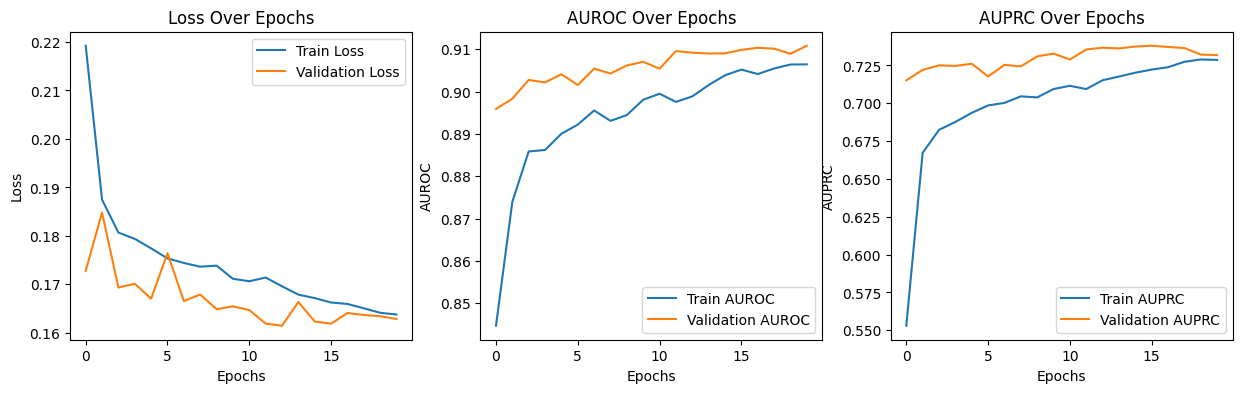

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.1807
Test Accuracy: 0.9411
Test AUC: 0.8943
Test PR AUC: 0.6858


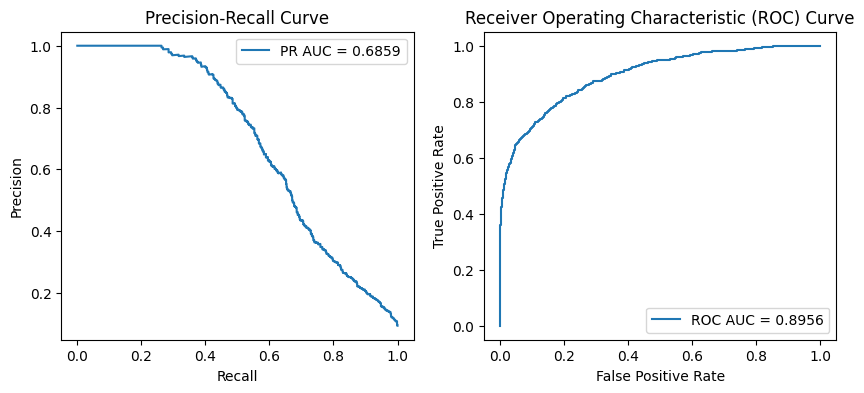

In [ ]:
# Modeling 6h df
metrics, los, death = process_metrics(df)
LSTM_all(metrics, los, death, interval = 6, lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

Epoch 1/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9109 - loss: 0.2444 - pr_auc: 0.4875 - roc_auc: 0.8131 - val_accuracy: 0.9479 - val_loss: 0.1709 - val_pr_auc: 0.7236 - val_roc_auc: 0.9013
Epoch 2/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9469 - loss: 0.1720 - pr_auc: 0.7054 - roc_auc: 0.8900 - val_accuracy: 0.9476 - val_loss: 0.1670 - val_pr_auc: 0.7246 - val_roc_auc: 0.9025
Epoch 3/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9444 - loss: 0.1755 - pr_auc: 0.6954 - roc_auc: 0.8912 - val_accuracy: 0.9474 - val_loss: 0.1661 - val_pr_auc: 0.7310 - val_roc_auc: 0.9060
Epoch 4/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9453 - loss: 0.1715 - pr_auc: 0.7017 - roc_auc: 0.8972 - val_accuracy: 0.9466 - val_loss: 0.1648 - val_pr_auc: 0.7268 - val_roc_auc: 0.9065
Epoch 5/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9449 - loss: 0.1696 - pr_auc: 0.7093 - roc_auc: 0.9004 - val_accuracy: 0.9461 - val_loss: 0.1647 - val_pr_auc

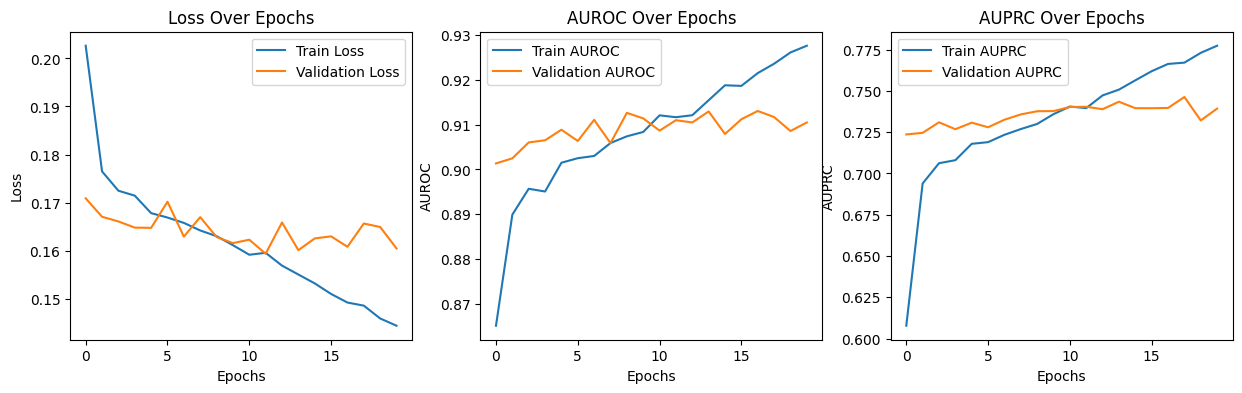

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.1816
Test Accuracy: 0.9405
Test AUC: 0.8983
Test PR AUC: 0.7060


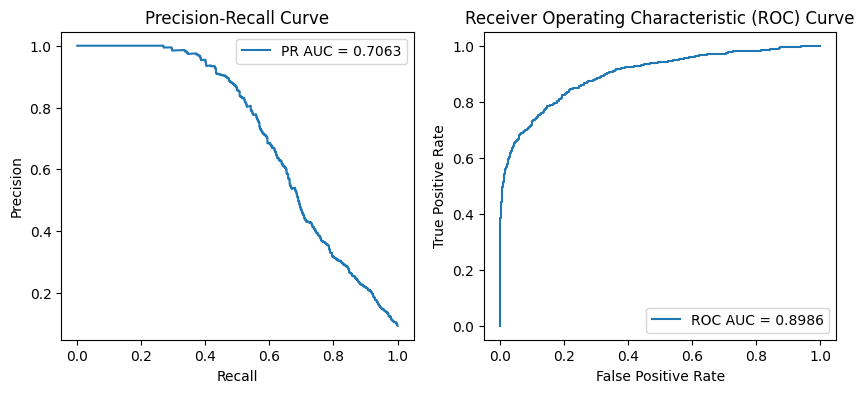

In [ ]:
# Rerun the whole process for 2h df
metrics, los, death = process_metrics(df2)
LSTM_all(metrics, los, death, interval = 2, lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

### All Available Components

In [ ]:
def process_all(df):
    all_cols = ['ICUSTAY_ID', 'ADMISSION_TYPE', 'GCS', 'MAP', 'VENT', 'FiO2', 'PaO2',
          'Platelets', 'Bilirubin', 'Creatinine', 'Urine', 'Dopamine',
          'Dobutamine', 'Epinephrine', 'Norepinephrine', 'SOFA', 'SOFA_chg',
          'HeartRate', 'Respiratory_Rate', 'Temperature', 'OASIS',
          'OASIS_chg', 'PRE_ICU_LEN', 'AGE']

    all_df = df[all_cols]
    static_df = icu[['ICUSTAY_ID','DEATH','LOS']]
    all_df = pd.merge(all_df, static_df, on='ICUSTAY_ID')

    # Heat Map for correlation
    correlation_matrix = all_df[all_df.columns[2:]].corr() # Exclude categorical features
    plt.figure(figsize=(20, 20))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
    plt.title("Correlation Heatmap")
    plt.show()

    static = all_df.groupby('ICUSTAY_ID')[['PRE_ICU_LEN', 'AGE', 'ADMISSION_TYPE','LOS']].first()
    death = all_df.groupby('ICUSTAY_ID')['DEATH'].first()

    # Delete cols 'PRE_ICU_LEN', 'AGE', 'ADMISSION_TYPE', 'Death' from all_df
    all_df = all_df.drop(columns=['PRE_ICU_LEN', 'AGE', 'ADMISSION_TYPE', 'LOS', 'DEATH'])

    # Preprocess: Standardize numerical
    scaler = MinMaxScaler()
    all_df[all_df.columns[1:]] = scaler.fit_transform(all_df[all_df.columns[1:]])
    static[['PRE_ICU_LEN', 'AGE', 'LOS']] = scaler.fit_transform(static[['PRE_ICU_LEN', 'AGE', 'LOS']])

    # Process null value
    for col in all_df.columns[1:]:
          all_df[col] = all_df[col].fillna(-100) # Will be ingnored when masked

    # Encode catagorical feature
    encoder = LabelEncoder()
    static['ADMISSION_TYPE'] = encoder.fit_transform(static['ADMISSION_TYPE'])

    all = all_df.groupby('ICUSTAY_ID')[all_df.columns[1:]].apply(lambda x: x.values.tolist())
    return all, static, death

- 6h Dataset

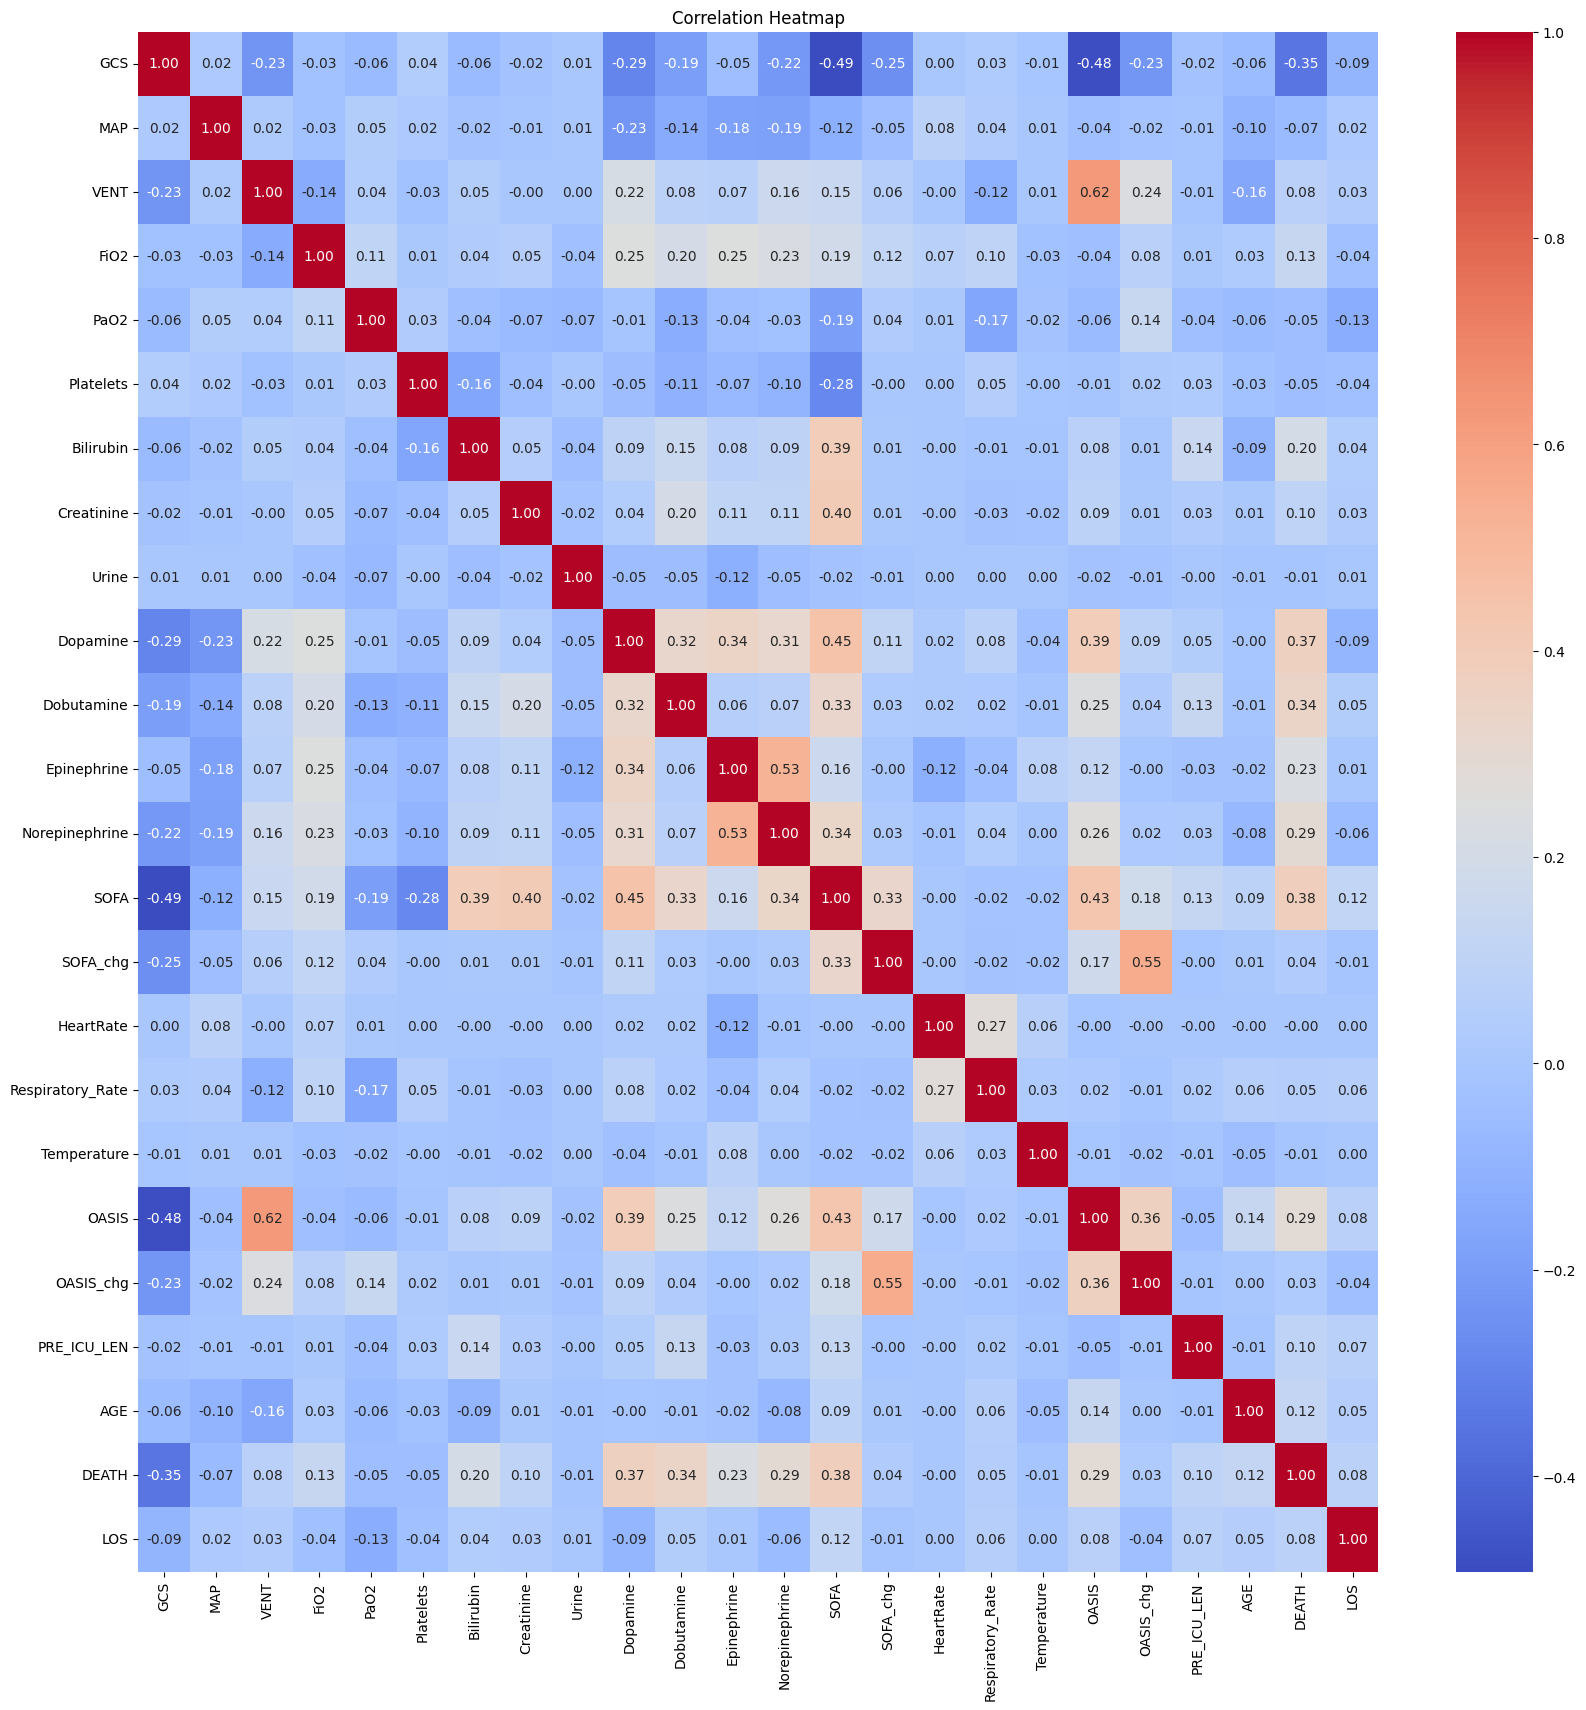

In [ ]:
# Preprocess
all, static, death = process_all(df)

Epoch 1/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9046 - loss: 0.2975 - pr_auc: 0.3323 - roc_auc: 0.7320 - val_accuracy: 0.9285 - val_loss: 0.2194 - val_pr_auc: 0.5842 - val_roc_auc: 0.8481
Epoch 2/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9287 - loss: 0.2211 - pr_auc: 0.5151 - roc_auc: 0.8268 - val_accuracy: 0.9328 - val_loss: 0.2076 - val_pr_auc: 0.5876 - val_roc_auc: 0.8553
Epoch 3/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9316 - loss: 0.2129 - pr_auc: 0.5454 - roc_auc: 0.8409 - val_accuracy: 0.9335 - val_loss: 0.2060 - val_pr_auc: 0.5965 - val_roc_auc: 0.8578
Epoch 4/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9353 - loss: 0.2014 - pr_auc: 0.5983 - roc_auc: 0.8593 - val_accuracy: 0.9332 - val_loss: 0.2048 - val_pr_auc: 0.6001 - val_roc_auc: 0.8657
Epoch 5/20
677/677 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9295 - loss: 0.2124 - pr_auc: 0.5802 - roc_auc: 0.8503 - val_accuracy: 0.9311 - val_loss: 0.2021 - val_pr_auc:

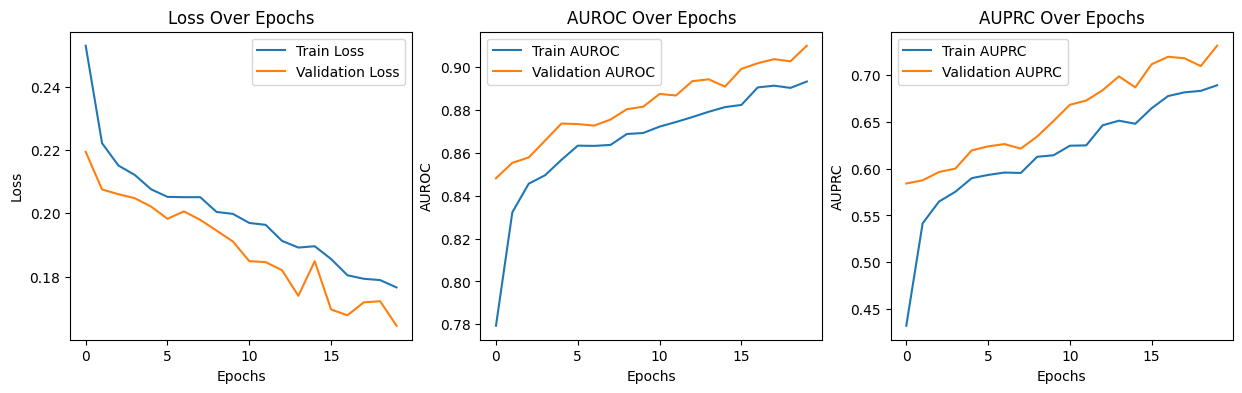

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.1783
Test Accuracy: 0.9465
Test AUC: 0.8894
Test PR AUC: 0.6876


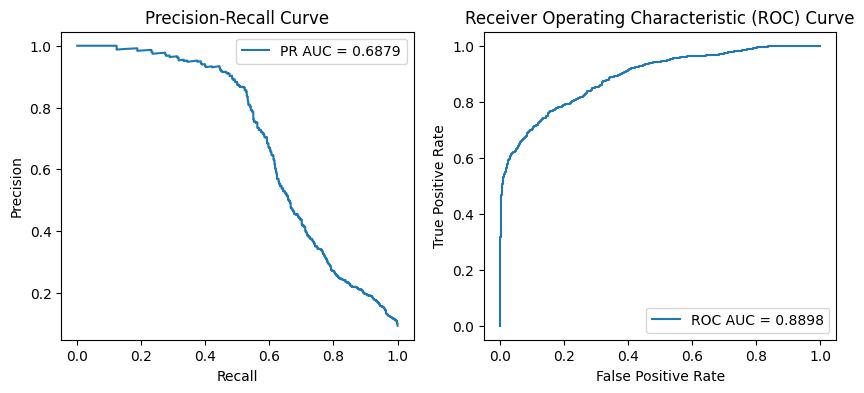

In [ ]:
# Modeling
LSTM_all(all, static, death, interval = 6, lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

- 2h Dataset

In [ ]:
# Rerun the whole process for 2h df
all, static, death = process_all(df2)

Epoch 1/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8916 - loss: 0.2853 - pr_auc: 0.3328 - roc_auc: 0.7538 - val_accuracy: 0.9302 - val_loss: 0.2078 - val_pr_auc: 0.5892 - val_roc_auc: 0.8598
Epoch 2/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9294 - loss: 0.2159 - pr_auc: 0.5445 - roc_auc: 0.8280 - val_accuracy: 0.9315 - val_loss: 0.2093 - val_pr_auc: 0.5905 - val_roc_auc: 0.8601
Epoch 3/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9338 - loss: 0.2028 - pr_auc: 0.5898 - roc_auc: 0.8551 - val_accuracy: 0.9346 - val_loss: 0.2044 - val_pr_auc: 0.6130 - val_roc_auc: 0.8741
Epoch 4/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9301 - loss: 0.2130 - pr_auc: 0.5812 - roc_auc: 0.8495 - val_accuracy: 0.9315 - val_loss: 0.2011 - val_pr_auc: 0.6141 - val_roc_auc: 0.8779
Epoch 5/20
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9274 - loss: 0.2127 - pr_auc: 0.5977 - roc_auc: 0.8589 - val_accuracy: 0.9361 - val_loss: 0.1959 - val_pr_auc

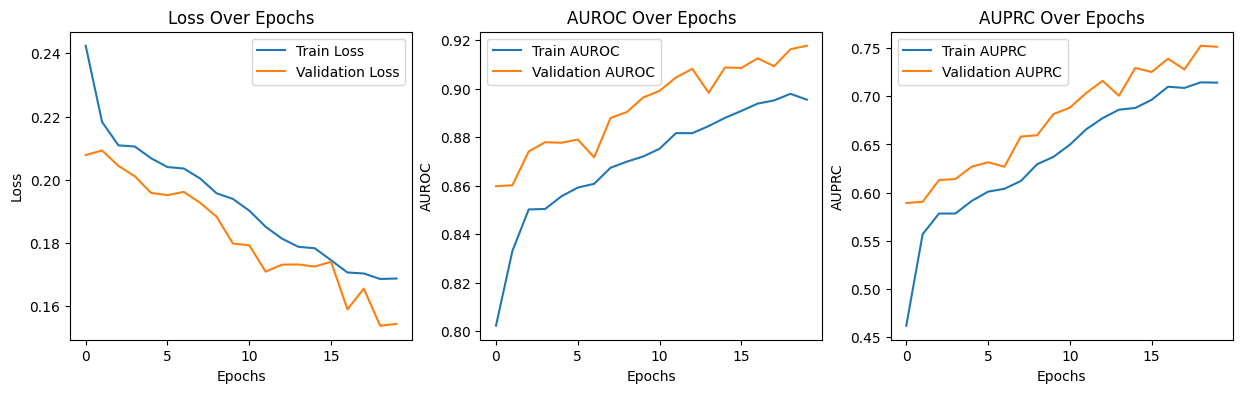

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Loss: 0.1701
Test Accuracy: 0.9484
Test AUC: 0.8966
Test PR AUC: 0.7060


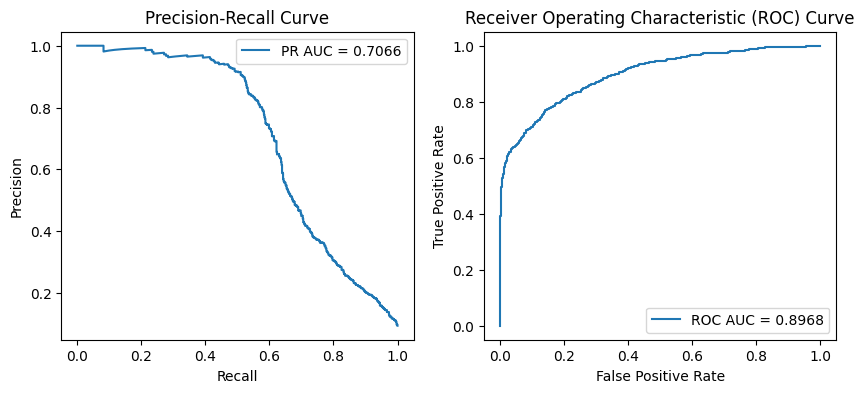

In [ ]:
LSTM_all(all, static, death, interval = 2, lstm_units = 64, dropout_rate = 0.2, dense_units = 32, batch_size = 32)

# Experiment 3: LSTM v.s. Baseline Model XGBoost (6h & 2h with Major Metrics)
- Compare LSTM with the baseline model XGBoost that can’t leverage the nature of time series data
- LSTM: Our proposed method of time series metrics (SOFA, SOFA_chg, OASIS, OASIS_chg, LOS)
- Baseline XGBoost: Average of the last 24 hours data
- Compare performance of time interval of 6h v.s. 2h

In [ ]:
def process_metrics(df):
    metrics_cols = ['SOFA', 'SOFA_chg', 'OASIS', 'OASIS_chg', 'ICUSTAY_ID','TIME']
    metrics_df = df[metrics_cols]

    static_df = icu[['ICUSTAY_ID','DEATH','LOS']]
    metrics_df = pd.merge(metrics_df, static_df, on='ICUSTAY_ID')

    # Extract the last 24 hours data
    metrics_df['TIME'] = pd.to_datetime(metrics_df['TIME'])
    metrics_df['MAX_TIME'] = metrics_df.groupby('ICUSTAY_ID')['TIME'].transform('max')
    metrics_df = metrics_df[metrics_df['TIME'] >= metrics_df['MAX_TIME'] - pd.Timedelta(hours=24)]

    metrics = metrics_df.groupby('ICUSTAY_ID')[['SOFA', 'SOFA_chg','OASIS','OASIS_chg', 'LOS']].mean()
    death = metrics_df.groupby('ICUSTAY_ID')['DEATH'].first()
    return metrics, death

In [ ]:
def xgboost(metrics,death):
    X = metrics.values
    y = death.values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

    xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    xgb_model.fit(X_train, y_train)

    y_pred = xgb_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    y_train_prob = xgb_model.predict_proba(X_train)[:, 1]
    y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

    print(f"Test Accuracy: {accuracy:.4f}")
    plot_curves(y_test, y_test_prob)

/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [20:13:58] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Test Accuracy: 0.9357


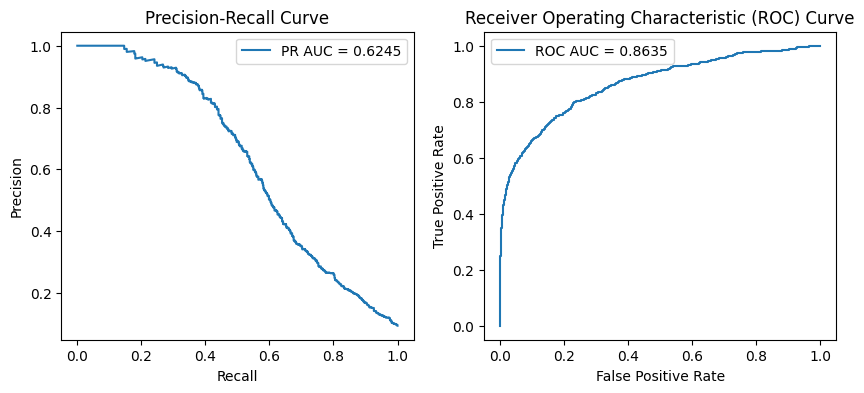

In [ ]:
metrics, death = process_metrics(df)
xgboost(metrics, death)

/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [20:15:50] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Test Accuracy: 0.9360


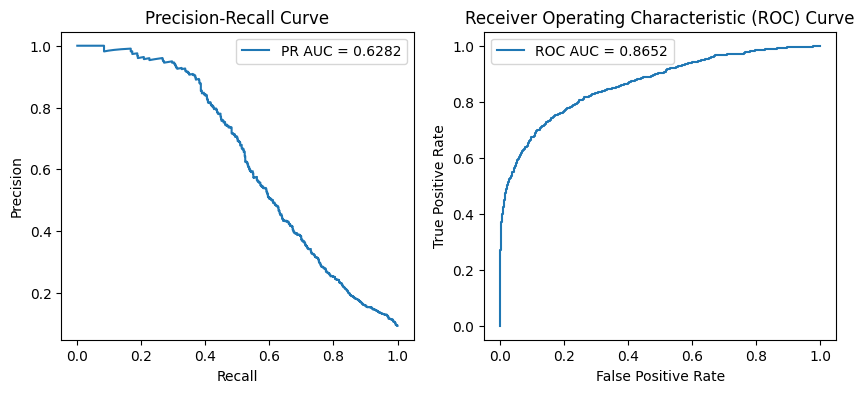

In [ ]:
metrics, death = process_metrics(df2)
xgboost(metrics, death)